### Add complete ORF1B p-distance values to the table with PCR-fragment p-distance values

In [1]:
import pandas as pd

pcr = pd.read_csv("pairs_pcr_orf1b_only_ICTV_headers.csv")
comp = pd.read_csv("pairs_complete_orf1b_only_ICTV_headers.csv")

pcr = pcr.rename(columns={"value.x": "nt p-distance pcr", "value.y": "aa p-distance pcr"})
comp = comp.rename(columns={"value.x": "nt p-distance complete", "value.y": "aa p-distance complete"})

merged = pcr.merge(comp, on=["row", "col"], how="left")

merged.to_csv("pairs_pcr_and_complete_only_ICTV_headers.csv", index=False)

print(merged.head())
print("rows:", len(merged), "| missing complete:", merged["nt p-distance complete"].isna().sum())

                                                 row  \
0  AB823731/BTN/Homo-sapiens-16-months-old-male/2...   
1  AB823731/BTN/Homo-sapiens-16-months-old-male/2...   
2  AB823731/BTN/Homo-sapiens-16-months-old-male/2...   
3  AB823731/BTN/Homo-sapiens-16-months-old-male/2...   
4  AB823731/BTN/Homo-sapiens-16-months-old-male/2...   

                                                 col  nt p-distance pcr  \
0  AB823731/BTN/Homo-sapiens-16-months-old-male/2...           0.000000   
1  AB823732/BTN/Homo-sapiens-1-months-old-male/20...           0.002755   
2  AB829252/TUR/Homo-sapiens--24-months-old-femai...           0.267218   
3            AF141381/NA/NA/NA/Mamastrovirus-hominis           0.418733   
4            AF260508/NA/NA/NA/Mamastrovirus-hominis           0.385675   

   aa p-distance pcr  nt p-distance complete  aa p-distance complete  
0           0.000000                0.000000                0.000000  
1           0.000000                0.000682                0.000000  

### Check species relations (same or different)

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = merged

def get_species(name):
    if pd.isna(name):
        return None
    parts = str(name).split("/")
    sp = parts[-1].strip()
    #print(sp)
    if sp == "" or sp == "NA" or sp.lower() == "nan":
        return None
    return sp

df["species_row"] = df["row"].apply(get_species)
df["species_col"] = df["col"].apply(get_species)

def _is_missing(x):
    if x is None:
        return True
    try:
        if pd.isna(x):          # catches np.nan, pd.NA, NaT
            return True
    except (TypeError, ValueError):
        pass
    s = str(x).strip().lower()
    return s in {"", "na", "n/a", "nan", "none", "null"}

def species_relation(r, c):
    if _is_missing(r) or _is_missing(c):
        return "unknown"
    return "same" if r == c else "different"

df["species_relation"] = [
    species_relation(r, c) for r, c in zip(df["species_row"], df["species_col"])
]

df[["row", "species_row", "col", "species_col", "species_relation"]]

,row,species_row,col,species_col,species_relation
0,AB823731/BTN/Homo-sapiens-16-months-old-male/2...,Mamastrovirus-melbournense,AB823731/BTN/Homo-sapiens-16-months-old-male/2...,Mamastrovirus-melbournense,same
1,AB823731/BTN/Homo-sapiens-16-months-old-male/2...,Mamastrovirus-melbournense,AB823732/BTN/Homo-sapiens-1-months-old-male/20...,Mamastrovirus-melbournense,same
2,AB823731/BTN/Homo-sapiens-16-months-old-male/2...,Mamastrovirus-melbournense,AB829252/TUR/Homo-sapiens--24-months-old-femai...,NaN,unknown
3,AB823731/BTN/Homo-sapiens-16-months-old-male/2...,Mamastrovirus-melbournense,AF141381/NA/NA/NA/Mamastrovirus-hominis,Mamastrovirus-hominis,different
4,AB823731/BTN/Homo-sapiens-16-months-old-male/2...,Mamastrovirus-melbournense,AF260508/NA/NA/NA/Mamastrovirus-hominis,Mamastrovirus-hominis,different
...,...,...,...,...,...
1106699,Z25771/NA/NA/NA/Mamastrovirus-hominis,Mamastrovirus-hominis,PX941856/CHN/Bos-taurus/2022/NA,NaN,unknown
1106700,Z25771/NA/NA/NA/Mamastrovirus-hominis,Mamastrovirus-hominis,PX942072/CHN/Bos-taurus/2022/NA,NaN,unknown
1106701,Z25771/NA/NA/NA/Mamastrovirus-hominis,Mamastrovirus-hominis,PZ146428/CHN/cow/2024/NA,NaN,unknown
1106702,Z25771/NA/NA/NA/Mamastrovirus-hominis,Mamastrovirus-hominis,Y15937/NA/sheep/NA/Mamastrovirus-ovis,Mamastrovirus-ovis,different


In [6]:
df["species_relation"].value_counts()

species_relation
unknown      859695
different    208358
same          38651
Name: count, dtype: int64

### Only keep rows with same species

In [11]:
mask_same = df["species_relation"] == "same"         
mask_dist = df["nt p-distance pcr"] > 0.2

same_species_gt02 = df[mask_same & mask_dist].copy()

print(f"same species: {mask_same.sum()}")
print(f"из них nt complete > 0.2: {len(same_species_gt02)}")
same_species_gt02

same species: 38651
из них nt complete > 0.2: 1478


,row,col,nt p-distance pcr,aa p-distance pcr,nt p-distance complete,aa p-distance complete,species_row,species_col,species_relation
3249,AF141381/NA/NA/NA/Mamastrovirus-hominis,KP862744/KOR/Homo-sapiens/2014/Mamastrovirus-h...,0.200542,0.048780,0.161943,0.054656,Mamastrovirus-hominis,Mamastrovirus-hominis,same
3490,AF141381/NA/NA/NA/Mamastrovirus-hominis,MK059952/USA/Homo-sapiens/NA/Mamastrovirus-hom...,0.200542,0.056911,0.168691,0.064777,Mamastrovirus-hominis,Mamastrovirus-hominis,same
40125,JF713713/USA/Sus-scrofa/2010/Mamastrovirus-sui...,KY940075/KEN/pig/2012/Mamastrovirus-suisvulgaris,0.273713,0.195122,0.246585,0.180328,Mamastrovirus-suisvulgaris,Mamastrovirus-suisvulgaris,same
40450,JF713713/USA/Sus-scrofa/2010/Mamastrovirus-sui...,MW504570/USA/Sus-scrofa/2018/Mamastrovirus-sui...,0.273713,0.178862,0.241120,0.174180,Mamastrovirus-suisvulgaris,Mamastrovirus-suisvulgaris,same
40482,JF713713/USA/Sus-scrofa/2010/Mamastrovirus-sui...,MW784084/CHN/NA/NA/Mamastrovirus-suisvulgaris,0.271003,0.162602,0.232923,0.168033,Mamastrovirus-suisvulgaris,Mamastrovirus-suisvulgaris,same
...,...,...,...,...,...,...,...,...,...
1023667,PV247174/IND/pig/2023/Mamastrovirus-suisorient...,KF787112/CHN/swine/2013/Mamastrovirus-suisorie...,0.246612,0.219512,0.217213,0.163934,Mamastrovirus-suisorientalis,Mamastrovirus-suisorientalis,same
1024053,PV247174/IND/pig/2023/Mamastrovirus-suisorient...,MW504546/USA/Sus-scrofa/2018/Mamastrovirus-sui...,0.243902,0.219512,0.217213,0.165984,Mamastrovirus-suisorientalis,Mamastrovirus-suisorientalis,same
1024167,PV247174/IND/pig/2023/Mamastrovirus-suisorient...,NC_025379/CHN/swine/2013/Mamastrovirus-suisori...,0.246612,0.219512,0.217213,0.163934,Mamastrovirus-suisorientalis,Mamastrovirus-suisorientalis,same
1024183,PV247174/IND/pig/2023/Mamastrovirus-suisorient...,OL689632/CHN/Porcine/2021/Mamastrovirus-suisor...,0.243902,0.227642,0.218579,0.172131,Mamastrovirus-suisorientalis,Mamastrovirus-suisorientalis,same


In [12]:
same_species_gt02["species_row"].value_counts()

species_row
Mamastrovirus-suisvulgaris       1040
Mamastrovirus-bovisorientalis     418
Mamastrovirus-suisorientalis       10
Mamastrovirus-hominis               4
Mamastrovirus-rattorientalis        4
Mamastrovirus-bubali                2
Name: count, dtype: int64

In [13]:
cols_to_save = ["row", "col", "species_row",
                "nt p-distance pcr", "aa p-distance pcr",
                "nt p-distance complete", "aa p-distance complete"]
same_species_gt02[cols_to_save].to_csv(
    "same_species_nt_pcr_gt02_only_ICTV_headers.csv", index=False
)

### ICTV and GenBank headers comparison

In [4]:
import pandas as pd

f1 = pd.read_csv("pairs_complete_orf1b_genbank_headers.csv") 
f2 = pd.read_csv("pairs_complete_orf1b_ictv_headers.csv")
assert len(f1) == len(f2)

r1, c1 = f1["row"].values, f1["col"].values
r2, c2 = f2["row"].values, f2["col"].values

dr = r1 != r2
dc = c1 != c2
mask = dr | dc

rows = []
for i in mask.nonzero()[0]:
    if dr[i]:
        rows.append((r1[i], r2[i]))
    if dc[i]:
        rows.append((c1[i], c2[i]))

seen = set()
uniq = []
for a, b in rows:
    if (b, a) in seen:
        continue
    seen.add((a, b))
    uniq.append((a, b))

out = pd.DataFrame(uniq, columns=["file1", "file2"])
#out.to_csv("header_differences.csv", index=False)
print(len(out))
out

37872


,file1,file2
0,GQ502193/USA/VA2-human-Stl-WD0680-2009/Homo-sa...,GQ502193/USA/VA2-human-Stl-WD0680-2009/Homo-sa...
1,GQ502193/USA/VA2-human-Stl-WD0680-2009/Homo-sa...,GQ502193/USA/VA2-human-Stl-WD0680-2009/Homo-sa...
2,GQ502193/USA/VA2-human-Stl-WD0680-2009/Homo-sa...,GQ502193/USA/VA2-human-Stl-WD0680-2009/Homo-sa...
3,GQ502193/USA/VA2-human-Stl-WD0680-2009/Homo-sa...,GQ502193/USA/VA2-human-Stl-WD0680-2009/Homo-sa...
4,LT898424/NA/PAstV-GER-L00919-K17_14-02-2014/NA...,LT898424/NA/PAstV-GER-L00919-K17_14-02-2014/NA...
...,...,...
37867,MW504577/USA/15217_AST_len_6652_cov_21.318023/...,MW504577/USA/15217_AST_len_6652_cov_21.318023/...
37868,OL695848/CHN/AH4-1/Sus-scrofa/2021/Mamastrovir...,OL695848/CHN/AH4-1/Sus-scrofa/2021/Mamastrovir...
37869,OL695848/CHN/AH4-1/Sus-scrofa/2021/Mamastrovir...,OL695848/CHN/AH4-1/Sus-scrofa/2021/Mamastrovir...
37870,OL695850/CHN/AH4-3/Sus-scrofa/2021/Mamastrovir...,OL695850/CHN/AH4-3/Sus-scrofa/2021/Mamastrovir...


### PCR-fragment nucleotide p-distance distributions in different ranges of complete ORF1B nucleotide p-pidstance distribution

In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110


df = pd.read_csv("pairs_pcr_and_complete_only_ICTV_headers.csv", sep=",") 

df = df.rename(columns={
    "nt p-distance pcr": "nt_pcr",
    "nt p-distance complete": "nt_complete",
    "aa p-distance pcr": "aa_pcr",
    "aa p-distance complete": "aa_complete",
})

# убираем дубли пар (A-B и B-A)
#df["pair_key"] = df.apply(lambda r: tuple(sorted([r["row"], r["col"]])), axis=1)
#df = df.drop_duplicates("pair_key").drop(columns="pair_key").reset_index(drop=True)

df

,row,col,nt_pcr,aa_pcr,nt_complete,aa_complete
0,AB823731/BTN/Homo-sapiens-16-months-old-male/2...,AB823731/BTN/Homo-sapiens-16-months-old-male/2...,0.000000,0.000000,0.000000,0.000000
1,AB823731/BTN/Homo-sapiens-16-months-old-male/2...,AB823732/BTN/Homo-sapiens-1-months-old-male/20...,0.002755,0.000000,0.000682,0.000000
2,AB823731/BTN/Homo-sapiens-16-months-old-male/2...,AB829252/TUR/Homo-sapiens--24-months-old-femai...,0.267218,0.223140,0.233810,0.190184
3,AB823731/BTN/Homo-sapiens-16-months-old-male/2...,AF141381/NA/NA/NA/Mamastrovirus-hominis,0.418733,0.454545,0.416838,0.439425
4,AB823731/BTN/Homo-sapiens-16-months-old-male/2...,AF260508/NA/NA/NA/Mamastrovirus-hominis,0.385675,0.462810,0.404517,0.433265
...,...,...,...,...,...,...
1106699,Z25771/NA/NA/NA/Mamastrovirus-hominis,PX941856/CHN/Bos-taurus/2022/NA,0.417344,0.447154,0.441860,0.473573
1106700,Z25771/NA/NA/NA/Mamastrovirus-hominis,PX942072/CHN/Bos-taurus/2022/NA,0.327913,0.300813,0.398051,0.384134
1106701,Z25771/NA/NA/NA/Mamastrovirus-hominis,PZ146428/CHN/cow/2024/NA,0.406504,0.463415,0.447386,0.484725
1106702,Z25771/NA/NA/NA/Mamastrovirus-hominis,Y15937/NA/sheep/NA/Mamastrovirus-ovis,0.384824,0.447154,0.436992,0.481707


In [16]:
def get_species(name):
    if pd.isna(name):
        return None
    parts = str(name).split("/")
    sp = parts[-1].strip()
    #print(sp)
    if sp == "" or sp == "NA" or sp.lower() == "nan":
        return None
    return sp

df["sp_row"] = df["row"].apply(get_species)
df["sp_col"] = df["col"].apply(get_species)

def _is_missing(x):
    if x is None:
        return True
    try:
        if pd.isna(x):          # catches np.nan, pd.NA, NaT
            return True
    except (TypeError, ValueError):
        pass
    s = str(x).strip().lower()
    return s in {"", "na", "n/a", "nan", "none", "null"}

def species_relation(r, c):
    if _is_missing(r) or _is_missing(c):
        return "unknown"
    return "same" if r == c else "different"

df["same_species"] = [
    species_relation(r, c) for r, c in zip(df["sp_row"], df["sp_col"])
]

df[["row", "col", "sp_row", "sp_col", "same_species"]]

,row,col,sp_row,sp_col,same_species
0,AB823731/BTN/Homo-sapiens-16-months-old-male/2...,AB823731/BTN/Homo-sapiens-16-months-old-male/2...,Mamastrovirus-melbournense,Mamastrovirus-melbournense,same
1,AB823731/BTN/Homo-sapiens-16-months-old-male/2...,AB823732/BTN/Homo-sapiens-1-months-old-male/20...,Mamastrovirus-melbournense,Mamastrovirus-melbournense,same
2,AB823731/BTN/Homo-sapiens-16-months-old-male/2...,AB829252/TUR/Homo-sapiens--24-months-old-femai...,Mamastrovirus-melbournense,NaN,unknown
3,AB823731/BTN/Homo-sapiens-16-months-old-male/2...,AF141381/NA/NA/NA/Mamastrovirus-hominis,Mamastrovirus-melbournense,Mamastrovirus-hominis,different
4,AB823731/BTN/Homo-sapiens-16-months-old-male/2...,AF260508/NA/NA/NA/Mamastrovirus-hominis,Mamastrovirus-melbournense,Mamastrovirus-hominis,different
...,...,...,...,...,...
1106699,Z25771/NA/NA/NA/Mamastrovirus-hominis,PX941856/CHN/Bos-taurus/2022/NA,Mamastrovirus-hominis,NaN,unknown
1106700,Z25771/NA/NA/NA/Mamastrovirus-hominis,PX942072/CHN/Bos-taurus/2022/NA,Mamastrovirus-hominis,NaN,unknown
1106701,Z25771/NA/NA/NA/Mamastrovirus-hominis,PZ146428/CHN/cow/2024/NA,Mamastrovirus-hominis,NaN,unknown
1106702,Z25771/NA/NA/NA/Mamastrovirus-hominis,Y15937/NA/sheep/NA/Mamastrovirus-ovis,Mamastrovirus-hominis,Mamastrovirus-ovis,different


In [18]:
BIN_EDGES = np.arange(0.17, 0.2501, 0.01)  # 0.17, 0.18, ..., 0.25
BIN_LABELS = [f"{BIN_EDGES[i]:.2f}-{BIN_EDGES[i+1]:.2f}" for i in range(len(BIN_EDGES)-1)]

df["bin_complete"] = pd.cut(
    df["nt_complete"],
    bins=BIN_EDGES,
    labels=BIN_LABELS,
    include_lowest=True,
    right=False,
)

# сколько пар в каждом бине и сколько из них в каждом классе
summary = df.groupby(["bin_complete", "same_species"], observed=False).size().unstack(fill_value=0)
summary

same_species,no,unknown,yes
bin_complete,,,
0.17-0.18,34,354,4
0.18-0.19,110,778,30
0.19-0.20,216,2000,42
0.20-0.21,82,4844,136
0.21-0.22,88,5758,306
0.22-0.23,228,4934,590
0.23-0.24,382,6764,848
0.24-0.25,470,6578,390


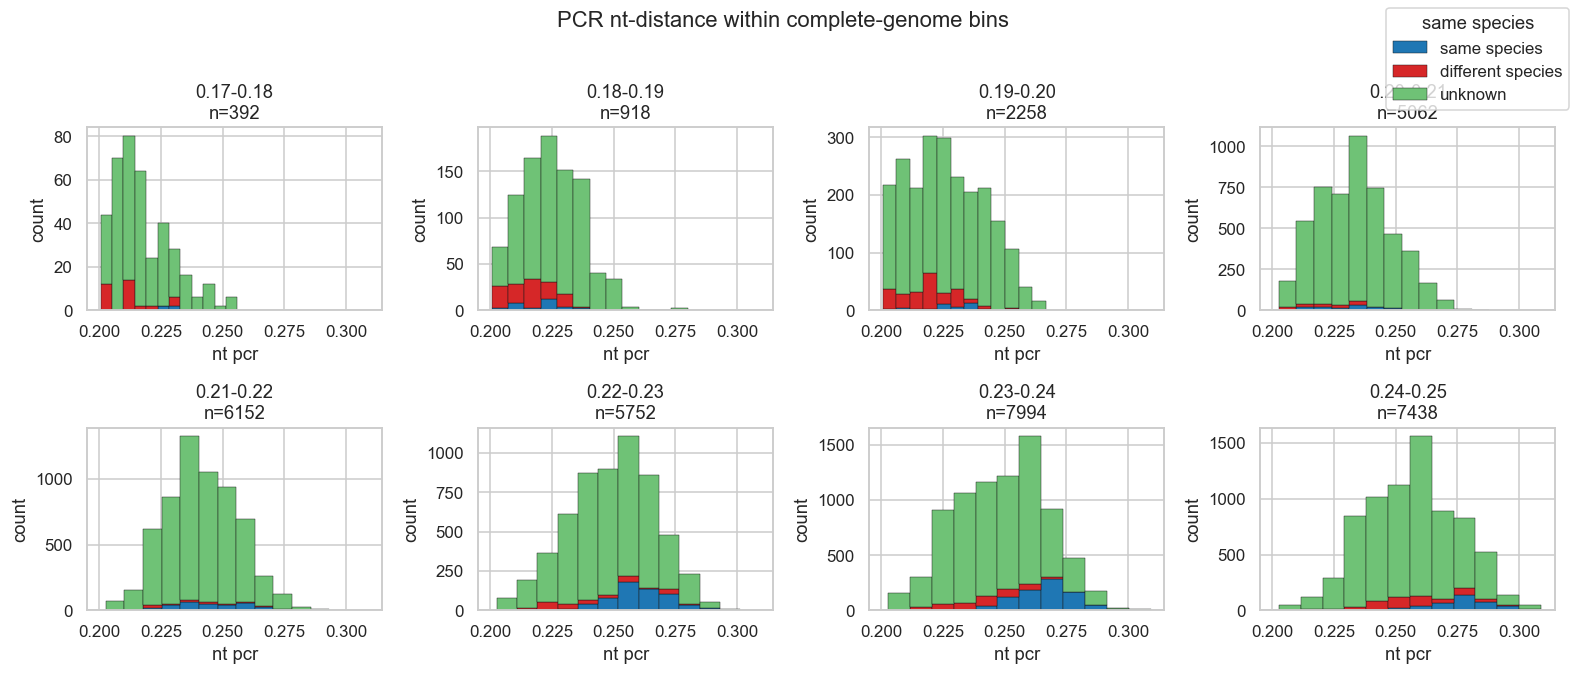

In [ ]:
bins_present = [b for b in BIN_LABELS if (df["bin_complete"] == b).any()]

df_plot = df.dropna(subset=["bin_complete", "nt_pcr"]).copy()

import matplotlib.ticker as mticker

n_cols = 4
n_rows = int(np.ceil(len(bins_present) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(3.6*n_cols, 3.0*n_rows),
                         sharex=True, sharey=False, squeeze=False)
axes = axes.ravel()

pal = {"yes": "#1f77b4", "no": "#d62728", "unknown": "#6fc276"}

for ax, lbl in zip(axes, bins_present):
    sub = df_plot[df_plot["bin_complete"] == lbl]
    arrays = [sub.loc[sub["same_species"] == s, "nt_pcr"].values
              for s in ["yes", "no", "unknown"]]
    ax.hist(arrays, bins=12, stacked=True,
            color=[pal["yes"], pal["no"], pal["unknown"]],
            edgecolor="k", linewidth=0.3,
            label=["yes", "no", "unknown"])
    ax.set_title(f"{lbl}\nn={len(sub)}")
    ax.set_xlabel("nt pcr")
    ax.set_ylabel("count")

for ax in axes[len(bins_present):]:
    ax.axis("off")

for ax in axes[:len(bins_present)]:
    ax.xaxis.set_tick_params(labelbottom=True)
    ax.xaxis.set_major_locator(mticker.MaxNLocator(nbins=5))

handles = [plt.Rectangle((0, 0), 1, 1, color=pal[s], ec="k", lw=0.3)
           for s in ["yes", "no", "unknown"]]
fig.legend(handles, ["same species", "different species", "unknown"],
           loc="upper right", title="same species")
fig.suptitle("PCR nt-distance within complete-genome bins", y=1.02)
plt.tight_layout()
plt.show()

n = 128802
same_species
unknown      87532
different    39588
same          1682
Name: count, dtype: int64


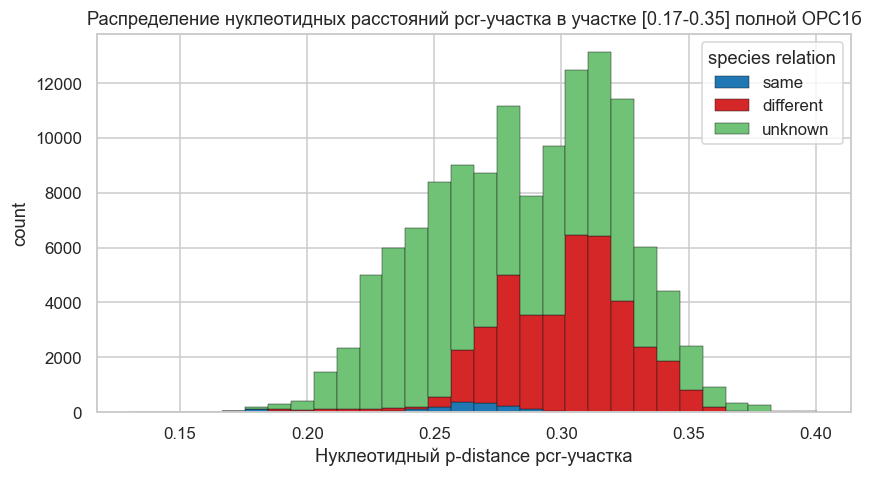

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

sub = df[(df["nt_complete"] >= 0.17) & (df["nt_complete"] < 0.35)].dropna(subset=["nt_pcr"])

print(f"n = {len(sub)}")
print(sub["same_species"].value_counts())

pal = {"same": "#1f77b4", "different": "#d62728", "unknown": "#6fc276"}
order = ["same", "different", "unknown"]

fig, ax = plt.subplots(figsize=(8, 4.5))

arrays = [sub.loc[sub["same_species"] == s, "nt_pcr"].values for s in order]
ax.hist(arrays, bins=30, stacked=True,
        color=[pal[s] for s in order],
        edgecolor="k", linewidth=0.3,
        label=order)

ax.set_xlabel("Нуклеотидный p-distance pcr-участка")
ax.set_ylabel("count")
ax.set_title(f"Распределение нуклеотидных расстояний pcr-участка в участке [0.17-0.35] полной ОРС1б")
ax.legend(title="species relation")
plt.tight_layout()
plt.show()

In [18]:
df

,row,col,nt_pcr,aa_pcr,nt_complete,aa_complete,sp_row,sp_col,same_species
0,AB823731/BTN/Homo-sapiens-16-months-old-male/2...,AB823731/BTN/Homo-sapiens-16-months-old-male/2...,0.000000,0.000000,0.000000,0.000000,Mamastrovirus-melbournense,Mamastrovirus-melbournense,same
1,AB823731/BTN/Homo-sapiens-16-months-old-male/2...,AB823732/BTN/Homo-sapiens-1-months-old-male/20...,0.002755,0.000000,0.000682,0.000000,Mamastrovirus-melbournense,Mamastrovirus-melbournense,same
2,AB823731/BTN/Homo-sapiens-16-months-old-male/2...,AB829252/TUR/Homo-sapiens--24-months-old-femai...,0.267218,0.223140,0.233810,0.190184,Mamastrovirus-melbournense,NaN,unknown
3,AB823731/BTN/Homo-sapiens-16-months-old-male/2...,AF141381/NA/NA/NA/Mamastrovirus-hominis,0.418733,0.454545,0.416838,0.439425,Mamastrovirus-melbournense,Mamastrovirus-hominis,different
4,AB823731/BTN/Homo-sapiens-16-months-old-male/2...,AF260508/NA/NA/NA/Mamastrovirus-hominis,0.385675,0.462810,0.404517,0.433265,Mamastrovirus-melbournense,Mamastrovirus-hominis,different
...,...,...,...,...,...,...,...,...,...
1106699,Z25771/NA/NA/NA/Mamastrovirus-hominis,PX941856/CHN/Bos-taurus/2022/NA,0.417344,0.447154,0.441860,0.473573,Mamastrovirus-hominis,NaN,unknown
1106700,Z25771/NA/NA/NA/Mamastrovirus-hominis,PX942072/CHN/Bos-taurus/2022/NA,0.327913,0.300813,0.398051,0.384134,Mamastrovirus-hominis,NaN,unknown
1106701,Z25771/NA/NA/NA/Mamastrovirus-hominis,PZ146428/CHN/cow/2024/NA,0.406504,0.463415,0.447386,0.484725,Mamastrovirus-hominis,NaN,unknown
1106702,Z25771/NA/NA/NA/Mamastrovirus-hominis,Y15937/NA/sheep/NA/Mamastrovirus-ovis,0.384824,0.447154,0.436992,0.481707,Mamastrovirus-hominis,Mamastrovirus-ovis,different
